In [8]:
import torch
from torch import Tensor, nn
from torch.optim import Optimizer
from torch.utils.data import DataLoader
from datasets import load_from_disk
import matplotlib.pyplot as plt

from pathlib import Path
from collections.abc import Callable
import sys

if "/content/src" not in sys.path:
    sys.path.insert(0, "/content/src")

from restore_pipeline.dataprocessing.dataloading import (
    DataConfig,
    get_damaged_splits_dataloaders,
)
from restore_pipeline.inpainting.unet import UNet
from restore_pipeline.inpainting.train_model import train_model

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
!unzip -oq "/content/drive/MyDrive/wikiart_train_processed.zip" -d /content

In [12]:
processed_path = Path("/content/wikiart_train_processed")
if not (processed_path / "dataset_info.json").is_file():
    raise FileNotFoundError(f"Saved WikiArt dataset not found at {processed_path.resolve()}")

In [14]:
cfg = DataConfig(processed_path=processed_path, batch_size=64, num_workers=2)
train_dl, val_dl, test_dl = get_damaged_splits_dataloaders(cfg)

In [15]:
batch = next(iter(train_dl))
damaged = batch["image"]   # model input
clean = batch["target"]    # reconstruction target
print(damaged.shape, clean.shape)

torch.Size([64, 3, 256, 256]) torch.Size([64, 3, 256, 256])


In [16]:
changed = (damaged - clean).abs().amax(dim=1) > 1e-6
changed_pixels = changed.flatten(1).sum(dim=1)

print("Changed pixels per image:", changed_pixels.tolist())

Changed pixels per image: [3008, 193, 2496, 1171, 2085, 3040, 1005, 1320, 3566, 2646, 524, 1467, 3922, 2305, 536, 816, 317, 1782, 438, 2816, 2274, 1354, 1094, 3907, 2536, 1553, 619, 1848, 2768, 3546, 437, 1518, 1280, 741, 2236, 2038, 945, 1523, 3280, 368, 1421, 980, 1167, 1378, 1405, 62, 1391, 3283, 3612, 2425, 2177, 1896, 2912, 2737, 762, 1265, 986, 274, 2923, 342, 1911, 1702, 1484, 2509]


In [17]:
ds = load_from_disk(str(cfg.processed_path))
print(ds.column_names)

['title', 'artist', 'date', 'genre', 'style', 'filename', 'image']


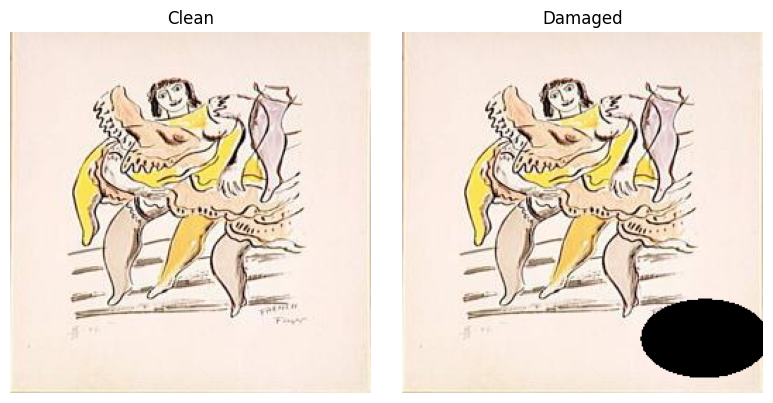

In [18]:
i = changed_pixels.argmax().item()  # Same index selects the matching clean and damaged images.

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, image, title in zip(axes, (clean[i], damaged[i]), ("Clean", "Damaged")):
    image = image.detach().cpu().permute(1, 2, 0)  # CHW → HWC
    ax.imshow(image.clamp(0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# U-Net on no styles

In [19]:
target_device = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)

In [20]:
history = {}

In [21]:
model = UNet(num_classes=3).to(target_device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.L1Loss()

In [23]:
checkpoint_path = (
    "/content/drive/MyDrive/"
    "uczenie_nienadzorowane/unet_no_styles_hybrid.pt"
)

history["no_styles"] = train_model(
    model,
    opt,
    train_dl,
    val_dl,
    test_dl,
    epochs=5,
    save_path=checkpoint_path,
    resume=True,
    checkpoint_every=100,
)

Device: cuda:0
Mixed precision: True
Training batches: 1287
Validation batches: 161
Epochs: 5
Checkpoint interval: 100 batches
Recovery checkpoint: /content/drive/MyDrive/uczenie_nienadzorowane/unet_no_styles_hybrid_resume.pt



Epoch 1/5 [Train]:   0%|          | 0/1287 [00:00<?, ?it/s]

Epoch 1/5 [Val masked L1]:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 01/5 | Train hybrid: 0.4118 | Val masked L1: 0.0884 | Time: 2079.9s | Best saved!


Epoch 2/5 [Train]:   0%|          | 0/1287 [00:00<?, ?it/s]

Epoch 2/5 [Val masked L1]:   0%|          | 0/161 [00:00<?, ?it/s]

... (8 outputs left out)

Epoch 5/5 [Val masked L1]:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 05/5 | Train hybrid: 0.0775 | Val masked L1: 0.0742 | Time: 2098.1s | Best saved!

Best epoch: 5 | Best masked val L1: 0.0742


Test masked L1:   0%|          | 0/161 [00:00<?, ?it/s]

Test masked L1: 0.0736


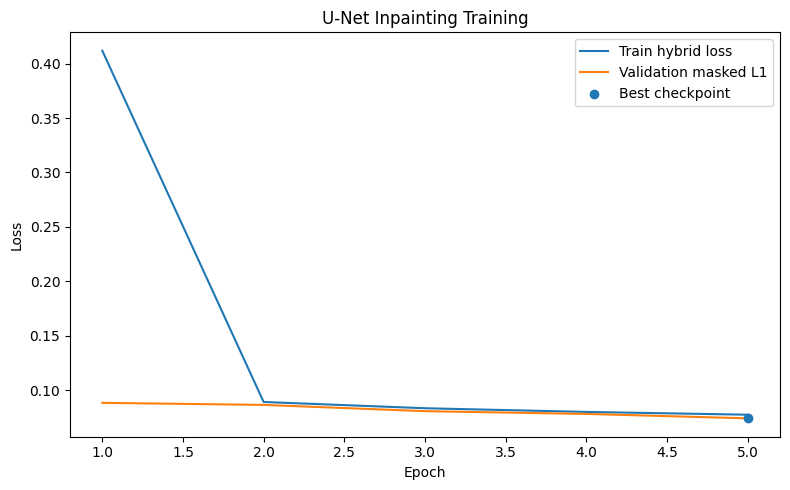

In [24]:
epochs = range(1, len(history["no_styles"]["val"]) + 1)
best_epoch = min(epochs, key=lambda e: history["no_styles"]["val"][e - 1])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, history["no_styles"]["train"], label="Train hybrid loss")
ax.plot(epochs, history["no_styles"]["val"], label="Validation masked L1")

ax.scatter(
    best_epoch,
    history["no_styles"]["val"][best_epoch - 1],
    label="Best checkpoint",
    zorder=5,
)

ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="U-Net Inpainting Training",
)

ax.legend()
fig.tight_layout()
plt.show()

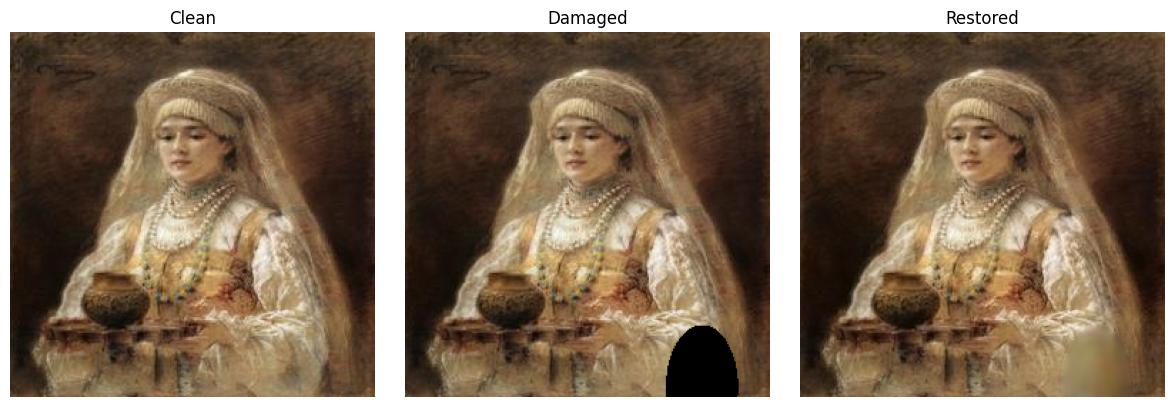

In [31]:
i = 4
device = next(model.parameters()).device

model.eval()
with torch.inference_mode():
    restored = model(damaged[i:i + 1].to(device))[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, image, title in zip(
    axes,
    (clean[i], damaged[i], restored),
    ("Clean", "Damaged", "Restored"),
):
    image = image.detach().cpu().permute(1, 2, 0)
    ax.imshow(image.clamp(0, 1))
    ax.set_title(title)
    ax.axis("off")

fig.tight_layout()
plt.show()